In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.cloud import bigquery
import os
import plotly.express as px
import polars as pl
import json

In [2]:
os.environ["GOOGLE_APPLICATION_CREDENTIALS"]="../.secrets/gcp_service_account.json"
client=bigquery.Client()
print("Gcp service account credentials loaded successfully.")

Gcp service account credentials loaded successfully.


In [3]:
df1="""
select * from `usgs-511715.usgs_dbt_marts.dim_earthquake_location`
"""
dim_earthquake_locations=pl.from_arrow(client.query(df1).result().to_arrow()
                         )

df2="""
select * from `usgs-511715.usgs_dbt_marts.fct_earthquake_events`
"""
fct_earthquake_events=pl.from_arrow(client.query(df2).result().to_arrow()
                         )

In [4]:
fct_earthquake_events=fct_earthquake_events.to_pandas()

In [5]:
fct_earthquake_events.isnull().sum()

earthquake_id                           0
network_id                              0
network_event_code                      0
event_type                              0
magnitude                               0
magnitude_type                          0
magnitude_severity_class                0
review_status                           0
alert_level                             0
has_tsunami_risk                        0
risk_profile_flag                       0
significance_score                      0
total_felt_reports                      0
max_reported_intensity              25255
instrumental_intensity              26254
total_stations_used                     0
min_station_distance                    0
rms_travel_time                         0
azimuthal_gap                           0
event_timestamp                         0
updated_timestamp                       0
event_hour                              0
event_day_of_week                       0
event_month_name                  

In [6]:
dim_earthquake_locations=dim_earthquake_locations.to_pandas()

In [7]:
dim_earthquake_locations.isna().sum()

earthquake_id                          0
place_description                      0
event_title                            0
geometry_type                          0
longitude                              0
latitude                               0
depth_km                               0
depth_category                         0
estimated_location_country_or_state    0
dtype: int64

In [8]:
dim_earthquake_locations.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29039 entries, 0 to 29038
Data columns (total 9 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   earthquake_id                        29039 non-null  object 
 1   place_description                    29039 non-null  object 
 2   event_title                          29039 non-null  object 
 3   geometry_type                        29039 non-null  object 
 4   longitude                            29039 non-null  float64
 5   latitude                             29039 non-null  float64
 6   depth_km                             29039 non-null  float64
 7   depth_category                       29039 non-null  object 
 8   estimated_location_country_or_state  29039 non-null  object 
dtypes: float64(3), object(6)
memory usage: 2.0+ MB


In [9]:
df=pd.merge(fct_earthquake_events, dim_earthquake_locations, on='earthquake_id', how='inner')
df

,earthquake_id,network_id,network_event_code,event_type,magnitude,magnitude_type,magnitude_severity_class,review_status,alert_level,has_tsunami_risk,...,event_month_name,pipeline_reporting_delay_minutes,place_description,event_title,geometry_type,longitude,latitude,depth_km,depth_category,estimated_location_country_or_state
0,aka2026icdgjp,ak,a2026icdgjp,earthquake,2.5,ml,Micro/Minor (< 3.0),reviewed,None,0,...,April,15513,"99 km SE of Akutan, Alaska","M 2.5 - 99 km SE of Akutan, Alaska",Point,-164.7400,-164.7400,-164.7400,Shallow (0-70 km),Alaska
1,us6000smc9,us,6000smc9,earthquake,2.5,ml,Micro/Minor (< 3.0),reviewed,None,0,...,April,113270,"83 km SE of False Pass, Alaska","M 2.5 - 83 km SE of False Pass, Alaska",Point,-162.6559,-162.6559,-162.6559,Shallow (0-70 km),Alaska
2,aka2026ibyxxy,ak,a2026ibyxxy,earthquake,2.5,ml,Micro/Minor (< 3.0),reviewed,None,0,...,April,3689,"95 km SE of Akutan, Alaska","M 2.5 - 95 km SE of Akutan, Alaska",Point,-164.7170,-164.7170,-164.7170,Shallow (0-70 km),Alaska
3,us6000st22,us,6000st22,earthquake,2.5,ml,Micro/Minor (< 3.0),reviewed,None,0,...,April,111078,"42 km S of False Pass, Alaska","M 2.5 - 42 km S of False Pass, Alaska",Point,-163.4913,-163.4913,-163.4913,Shallow (0-70 km),Alaska
4,aka2026goofif,ak,a2026goofif,earthquake,2.5,ml,Micro/Minor (< 3.0),reviewed,None,0,...,April,112035,"49 km NW of Beluga, Alaska","M 2.5 - 49 km NW of Beluga, Alaska",Point,-151.7920,-151.7920,-151.7920,Shallow (0-70 km),Alaska
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29034,us7000tiqc,us,7000tiqc,earthquake,6.4,mww,Strong/Strong (5.0 - 6.9),reviewed,green,0,...,September,32132,"50 km NNE of Kainantu, Papua New Guinea","M 6.4 - 50 km NNE of Kainantu, Papua New Guinea",Point,146.1073,146.1073,146.1073,Intermediate (70-300 km),Papua New Guinea
29035,us7000ti1p,us,7000ti1p,earthquake,6.5,mww,Strong/Strong (5.0 - 6.9),reviewed,green,1,...,September,40330,"177 km W of Nikolski, Alaska","M 6.5 - 177 km W of Nikolski, Alaska",Point,-171.5033,-171.5033,-171.5033,Shallow (0-70 km),Alaska
29036,us7000tgrk,us,7000tgrk,earthquake,6.5,mww,Strong/Strong (5.0 - 6.9),reviewed,green,0,...,September,48867,"121 km NNE of Teluknaga, Indonesia","M 6.5 - 121 km NNE of Teluknaga, Indonesia",Point,106.8682,106.8682,106.8682,Intermediate (70-300 km),Indonesia
29037,us6000txpi,us,6000txpi,earthquake,6.7,mww,Strong/Strong (5.0 - 6.9),reviewed,green,0,...,September,30729,"74 km ENE of Tadine, New Caledonia","M 6.7 - 74 km ENE of Tadine, New Caledonia",Point,168.5544,168.5544,168.5544,Intermediate (70-300 km),New Caledonia


In [10]:
Rate_of_event_type=df['event_type'].value_counts().reset_index()
Rate_of_event_type

,event_type,count
0,earthquake,28842
1,mining explosion,179
2,quarry blast,6
3,explosion,5
4,landslide,3
5,experimental explosion,2
6,accidental explosion,1
7,ice quake,1


In [11]:
fig_pie=px.pie(
    Rate_of_event_type,
    values="count",
    names="event_type",
    title="Event type distribution",
    template='plotly_dark',
    hole=.4
)
fig_pie.show()

In [12]:
df[['place_description','event_type']].value_counts().sort_values(ascending=False).head(10)

place_description                      event_type
south of the Fiji Islands              earthquake    321
South Sandwich Islands region          earthquake    269
Rat Islands, Aleutian Islands, Alaska  earthquake    205
Fiji region                            earthquake    182
Kermadec Islands region                earthquake    181
south of the Kermadec Islands          earthquake    167
Mid-Indian Ridge                       earthquake    121
Izu Islands, Japan region              earthquake    101
southern Mid-Atlantic Ridge            earthquake     99
Kermadec Islands, New Zealand          earthquake     76
Name: count, dtype: int64

In [13]:
blast_analysis=df[df['event_type']== 'quarry blast']

In [14]:
blast_analysis[['place_description','event_type']].value_counts().sort_values(ascending=False).head(10)

place_description            event_type  
10 km SE of Katie, Oklahoma  quarry blast    1
18 km E of Ferry, Alaska     quarry blast    1
2 km ENE of Aromas, CA       quarry blast    1
3 km S of Owasso, Oklahoma   quarry blast    1
3 km W of Salina, Oklahoma   quarry blast    1
5 km NE of Bradbury, CA      quarry blast    1
Name: count, dtype: int64

In [15]:
explosion_analysis=df[df['event_type']== 'explosion']

In [16]:
explosion_analysis[['place_description','event_type']].value_counts().sort_values(ascending=False).head(10)

place_description                    event_type
10 km E of Bonanza, Oregon           explosion     1
12 km S of Princeton, Canada         explosion     1
18 km NE of Amboy, Washington        explosion     1
5 km ESE of Benton City, Washington  explosion     1
5 km SSE of Monroe, Oregon           explosion     1
Name: count, dtype: int64

In [17]:
df.groupby('event_type')['depth_km'].mean().sort_values(ascending=False)

event_type
landslide                  85.312267
earthquake                -24.854660
experimental explosion    -79.527500
accidental explosion      -80.538000
mining explosion         -105.716540
quarry blast             -112.774194
explosion                -121.345067
ice quake                -141.540000
Name: depth_km, dtype: float64

In [18]:
df.groupby('event_type')['depth_category'].value_counts()

event_type              depth_category          
accidental explosion    Shallow (0-70 km)               1
earthquake              Shallow (0-70 km)           18407
                        Intermediate (70-300 km)    10435
experimental explosion  Shallow (0-70 km)               2
explosion               Shallow (0-70 km)               5
ice quake               Shallow (0-70 km)               1
landslide               Intermediate (70-300 km)        3
mining explosion        Shallow (0-70 km)             179
quarry blast            Shallow (0-70 km)               6
Name: count, dtype: int64

In [19]:
hour_event=df['event_hour'].value_counts().reset_index().sort_values(by='event_hour')

In [20]:
fig_line=px.line(
    hour_event,
    x='event_hour',
    y='count',
    title='Hourly Earthquake rate',
    template="plotly_white",
    markers=True,
    color_discrete_sequence=['#00cc96']
)
fig_line.show()
     

In [21]:
monthly_rate=df.groupby('event_month_name')['event_type'].value_counts().reset_index()
monthly_rate

,event_month_name,event_type,count
0,April,earthquake,2628
1,April,mining explosion,23
2,August,earthquake,2735
3,August,landslide,2
4,August,mining explosion,1
5,December,earthquake,2866
6,December,mining explosion,24
7,February,earthquake,2109
8,February,mining explosion,21
9,February,explosion,1


In [22]:
fig_bar=px.bar(
    monthly_rate,
    x="event_month_name",
    y="count",
    barmode="group",
    template='plotly_dark',
    color="event_type",
    color_continuous_scale='sunset'
)
fig_bar.show()

In [23]:
alert_count=df['alert_level'].value_counts()

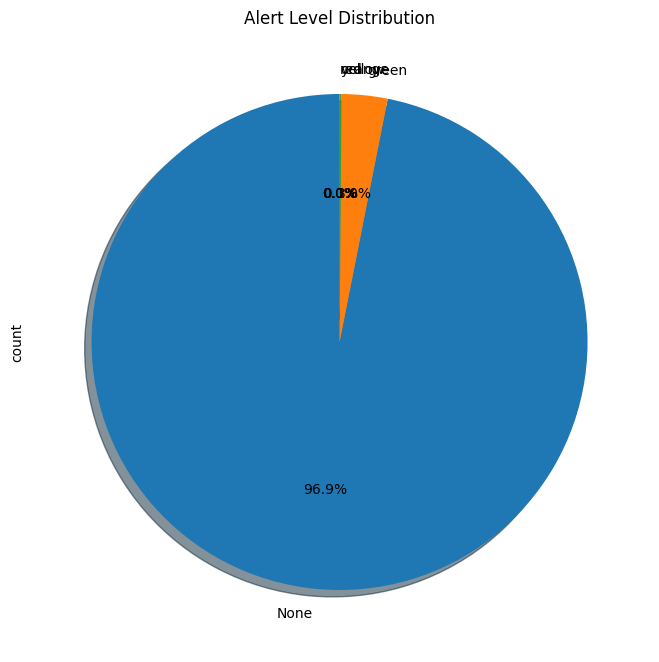

In [24]:
alert_count.plot.pie(
    autopct='%1.1f%%',
    startangle=90,
    shadow=True,
    figsize=(8, 10),
    title='Alert Level Distribution'
 
)

plt.show()


In [25]:
alert_analysis=df.groupby('event_hour')['alert_level'].value_counts().reset_index()
alert_analysis

,event_hour,alert_level,count
0,0,None,1185
1,0,green,28
2,1,None,1195
3,1,green,29
4,1,yellow,1
...,...,...,...
69,22,yellow,1
70,23,None,1196
71,23,green,43
72,23,yellow,2


In [26]:
fig_bar_alert=px.bar(
    alert_analysis,
    x='event_hour',
    y='count',
    barmode="group",
    template='plotly_dark',
    color='alert_level',
    title='Hourly Earthquake Alert Level Distribution'
)
fig_bar_alert.show()

In [27]:
df.groupby('estimated_location_country_or_state')['alert_level'].value_counts()

estimated_location_country_or_state  alert_level
2025 Hubbard Glacier Earthquake      green            1
Afghanistan                          None           144
                                     green            5
                                     orange           1
                                     yellow           1
                                                   ... 
west of Macquarie Island             green            6
west of the Galapagos Islands        None             5
western Indian-Antarctic Ridge       None            42
                                     green            4
western Xizang                       None            15
Name: count, Length: 419, dtype: int64

In [28]:
magnitude_analysis=df.groupby('magnitude_type')['alert_level'].value_counts().reset_index()

In [29]:
fig_sunburst=px.sunburst(
    magnitude_analysis,
    path=['count', 'alert_level', 'magnitude_type'],
)
fig_sunburst.show()

In [30]:
df['sensor_reliability_flag'] = np.where(
    (df['total_stations_used'] < 12) & (df['azimuthal_gap'] > 180), 
    'Low Reliability (Risky)', 
    'High Reliability (Solid)'
)

In [31]:
network_performance = df.groupby('sensor_reliability_flag').agg(
    total_events=('earthquake_id', 'count'),
    avg_pipeline_delay_mins=('pipeline_reporting_delay_minutes', 'mean'),
    avg_rms_travel_time=('rms_travel_time', 'mean')
).reset_index()
network_performance

,sensor_reliability_flag,total_events,avg_pipeline_delay_mins,avg_rms_travel_time
0,High Reliability (Solid),27973,98515.558503,0.668896
1,Low Reliability (Risky),1066,53242.368668,0.368616


In [32]:
depth_severity_matrix = pd.crosstab(
    df['depth_category'], 
    df['magnitude_severity_class'], 
    margins=True
).sort_values(by='All', ascending=False)
depth_severity_matrix 

magnitude_severity_class,Light/Moderate (3.0 - 4.9),Major/Great (>= 7.0),Micro/Minor (< 3.0),Strong/Strong (5.0 - 6.9),All
depth_category,,,,,
All,18851,14,8223,1951,29039
Shallow (0-70 km),9923,7,7876,795,18601
Intermediate (70-300 km),8928,7,347,1156,10438


In [33]:
tsunami_impact = df.groupby('has_tsunami_risk').agg(
    avg_significance=('significance_score', 'mean'),
    max_reported_intensity=('max_reported_intensity', 'max'),
    avg_felt_reports=('total_felt_reports', 'mean')
).reset_index()
tsunami_impact

,has_tsunami_risk,avg_significance,max_reported_intensity,avg_felt_reports
0,0,233.902853,9.1,7.911383
1,1,506.024096,9.0,294.710843


In [34]:
hourly_trends = df.groupby('event_hour').agg(
    event_count=('earthquake_id', 'count'),
    avg_magnitude=('magnitude', 'mean'),
    total_public_reports=('total_felt_reports', 'sum')
).reset_index().sort_values(by='event_count', ascending=False)
hourly_trends

,event_hour,event_count,avg_magnitude,total_public_reports
8,8,1331,3.784484,40165
22,22,1285,3.840241,5257
10,10,1259,3.823388,3886
21,21,1250,3.806724,14014
6,6,1246,3.785438,7331
23,23,1242,3.803571,6664
7,7,1226,3.759516,15942
2,2,1226,3.742476,4243
1,1,1225,3.745401,24962
15,15,1222,3.722626,26836
